## Linear Regression

In [1]:
import pandas as pd

url = "http://byungwan.com/class/Coupon_Sample.xlsx"

In [3]:
coupon = pd.read_excel(url)
coupon.head()

,CID,Gender,Age,CClass,Discount,Visits,Email,SMS,MStatus,Purchases,Sales
0,1,0,41,2,0,1,0,1,1,1,0.92
1,2,0,41,1,0,0,0,0,0,0,0.00
2,3,0,30,2,0,3,0,0,0,1,1.54
3,4,0,28,2,0,2,0,0,0,2,0.88
4,5,1,24,2,1,5,0,0,0,2,0.53


In [5]:
coupon.isnull().values.any()

np.False_

In [7]:
coupon.columns.get_loc("Sales")

10

In [8]:
y = coupon.iloc[:, 10]

In [9]:
x = coupon.iloc[:, 1:10] #column 1~9

In [10]:
x.head()

,Gender,Age,CClass,Discount,Visits,Email,SMS,MStatus,Purchases
0,0,41,2,0,1,0,1,1,1
1,0,41,1,0,0,0,0,0,0
2,0,30,2,0,3,0,0,0,1
3,0,28,2,0,2,0,0,0,2
4,1,24,2,1,5,0,0,0,2


In [11]:
from statsmodels import api as sm

In [12]:
x_c = sm.add_constant(x)

In [14]:
reg = sm.OLS(y, x_c).fit()
print(reg.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.727
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     144.8
Date:                Thu, 01 Oct 2026   Prob (F-statistic):          7.77e-132
Time:                        10:46:30   Log-Likelihood:                -340.75
No. Observations:                 499   AIC:                             701.5
Df Residuals:                     489   BIC:                             743.6
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.5064      0.126     -4.027      0.0

In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

In [22]:
vif_values = [float(vif(x.values, i)) for i in range(0,9)]

In [23]:
vif_labels = x.columns

In [24]:
pd.DataFrame({"Variable": vif_labels, "VIF Factor": vif_values})

,Variable,VIF Factor
0,Gender,1.367976
1,Age,9.885577
2,CClass,13.441381
3,Discount,1.489682
4,Visits,2.151796
5,Email,1.336097
6,SMS,1.438508
7,MStatus,1.248411
8,Purchases,3.359964


In [27]:
corrs = coupon.corr()

In [28]:
from matplotlib import pyplot as plt
import seaborn as sns

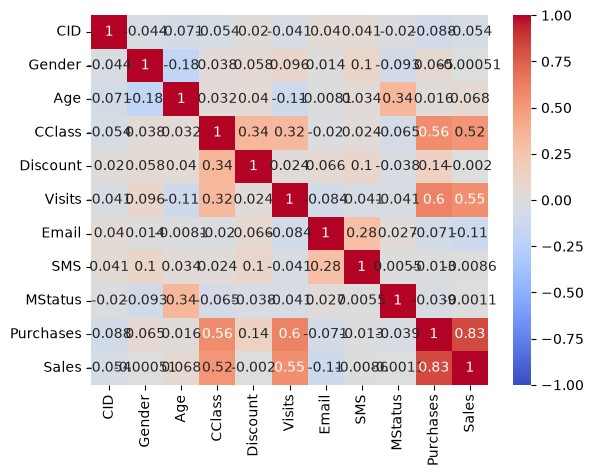

In [31]:
sns.heatmap(corrs, vmin = -1, vmax=1, center=0, cmap="coolwarm", annot=True)
plt.show()

In [32]:
coupon.head()

,CID,Gender,Age,CClass,Discount,Visits,Email,SMS,MStatus,Purchases,Sales
0,1,0,41,2,0,1,0,1,1,1,0.92
1,2,0,41,1,0,0,0,0,0,0,0.00
2,3,0,30,2,0,3,0,0,0,1,1.54
3,4,0,28,2,0,2,0,0,0,2,0.88
4,5,1,24,2,1,5,0,0,0,2,0.53


In [42]:
x2 = coupon.iloc[:, [1,2,4,5,6,7,8,9]]

In [38]:
x2_c = sm.add_constant(x2)

reg2 = sm.OLS(y, x2_c).fit()
print(reg2.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.715
Model:                            OLS   Adj. R-squared:                  0.710
Method:                 Least Squares   F-statistic:                     153.6
Date:                Thu, 01 Oct 2026   Prob (F-statistic):          2.70e-128
Time:                        11:02:59   Log-Likelihood:                -351.74
No. Observations:                 499   AIC:                             721.5
Df Residuals:                     490   BIC:                             759.4
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1200      0.097     -1.237      0.2

In [41]:
[float(vif(x2.values, i)) for i in range(0,8)]

[1.3317950649978945,
 2.6360999897931077,
 1.3827125786678884,
 2.127923716922383,
 1.3277607638074975,
 1.437678883609407,
 1.2064813020020975,
 2.8697514886927684]

In [49]:
residual = reg2.resid

In [50]:
bp_test = sm.stats.het_breuschpagan(residual, x2_c)
bp_test

(np.float64(40.70567413192085),
 np.float64(2.366069502417195e-06),
 np.float64(5.440221272339799),
 np.float64(1.384215142518368e-06))

In [52]:
bp_test2 = [float(b) for b in bp_test]
bp_test2

[40.70567413192085,
 2.366069502417195e-06,
 5.440221272339799,
 1.384215142518368e-06]

In [53]:
labels = ["LM Statistics", "LM p-value", "F Statistics", "F p-value"]

In [55]:
pd.DataFrame(bp_test2, columns=["Value"], index = labels) #if LM p-value < 0.05, modification required

,Value
LM Statistics,40.705674
LM p-value,0.000002
F Statistics,5.440221
F p-value,0.000001


In [59]:
reg3 = sm.OLS(y, x2_c).fit(cov_type="HC3")
print(reg3.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.715
Model:                            OLS   Adj. R-squared:                  0.710
Method:                 Least Squares   F-statistic:                     45.42
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           1.85e-54
Time:                        11:14:56   Log-Likelihood:                -351.74
No. Observations:                 499   AIC:                             721.5
Df Residuals:                     490   BIC:                             759.4
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1200      0.098     -1.221      0.2